In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

df = pd.read_csv("Iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.info()
print("\nSpecies counts:\n", df["Species"].value_counts())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Species counts:
 Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [5]:
print("Missing values per column:\n", df.isnull().sum())

# Id is just a row number, it carries no information, so drop it
df = df.drop(columns=["Id"])

# Clean the species labels: "Iris-setosa" -> "setosa"
df["Species"] = df["Species"].str.replace("Iris-", "", regex=False)
df.head()

Missing values per column:
 Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
dups = df.duplicated().sum()
print("Duplicate rows:", dups)
print(df[df.duplicated(keep=False)])

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 3
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm    Species
9              4.9           3.1            1.5           0.1     setosa
34             4.9           3.1            1.5           0.1     setosa
37             4.9           3.1            1.5           0.1     setosa
101            5.8           2.7            5.1           1.9  virginica
142            5.8           2.7            5.1           1.9  virginica
Shape after removing duplicates: (147, 5)


In [7]:
dups = df.duplicated().sum()
print("Duplicate rows:", dups)
print(df[df.duplicated(keep=False)])

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Empty DataFrame
Columns: [SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species]
Index: []
Shape after removing duplicates: (147, 5)


In [8]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

outlier_summary = {}
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    outlier_summary[col] = {"lower": round(low, 2), "upper": round(high, 2), "n_outliers": mask.sum()}

pd.DataFrame(outlier_summary).T

,lower,upper,n_outliers
SepalLengthCm,3.15,8.35,0.0
SepalWidthCm,2.05,4.05,4.0
PetalLengthCm,-3.65,10.35,0.0
PetalWidthCm,-1.95,4.05,0.0


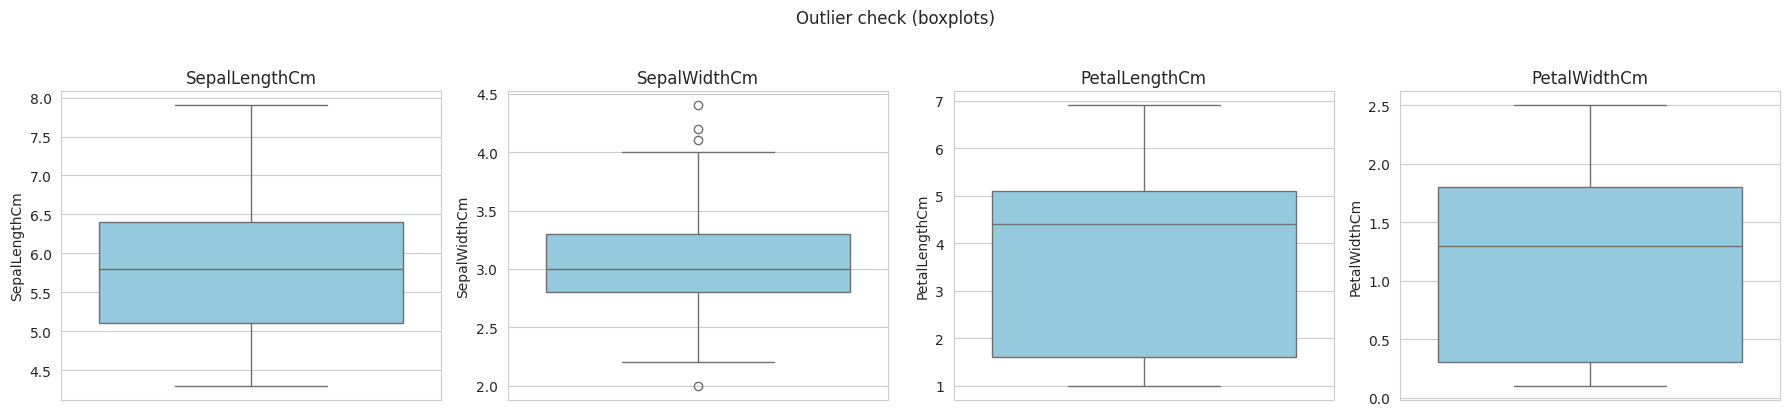

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.suptitle("Outlier check (boxplots)", y=1.03)
plt.tight_layout()
plt.show()

In [10]:
# Only 150 rows, and these values are real measurements (not errors),
# so we cap (winsorize) at the IQR fences instead of deleting rows.
df_clean = df.copy()
for col in features:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_clean[col] = df_clean[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print("Rows kept:", len(df_clean))
df_clean.describe()

Rows kept: 147


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,147.000000,147.000000,147.000000,147.000000
mean,5.856463,3.052381,3.780272,1.208844
std,0.829100,0.426331,1.759111,0.757874
min,4.300000,2.050000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.400000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.050000,6.900000,2.500000


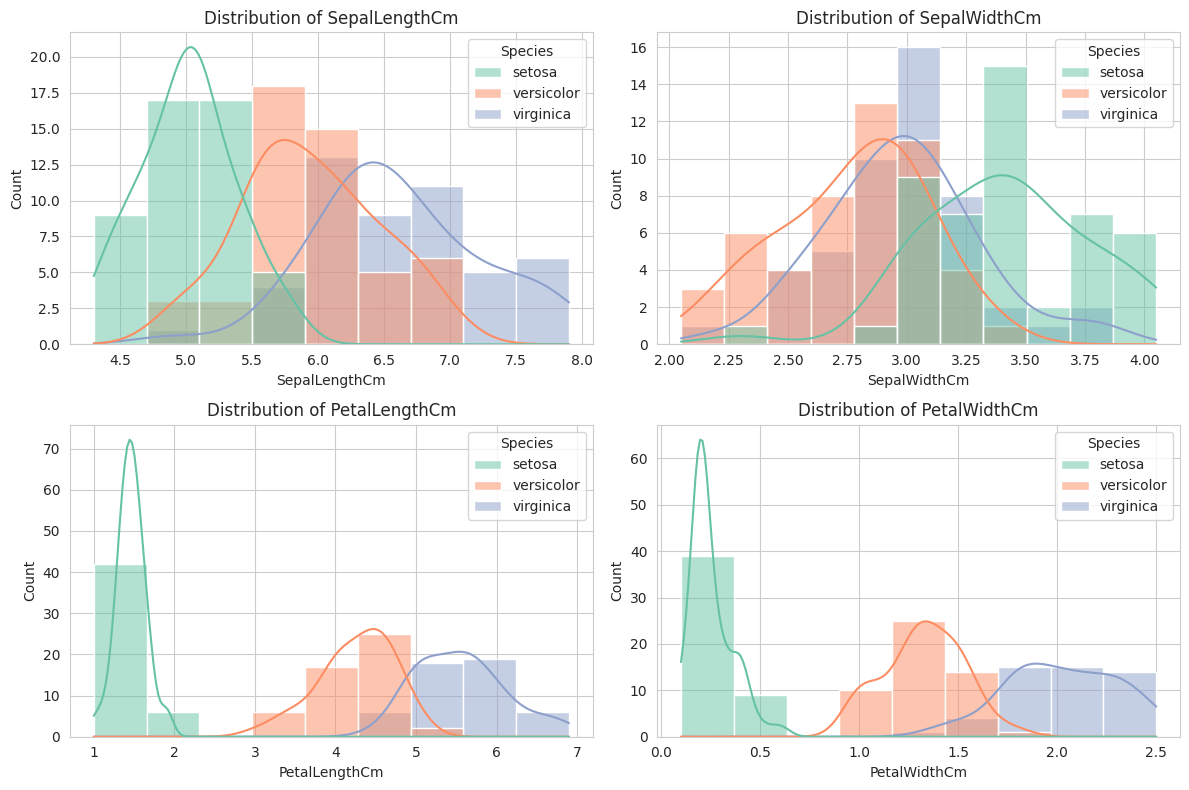

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df_clean, x=col, hue="Species", kde=True, ax=ax, palette="Set2")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

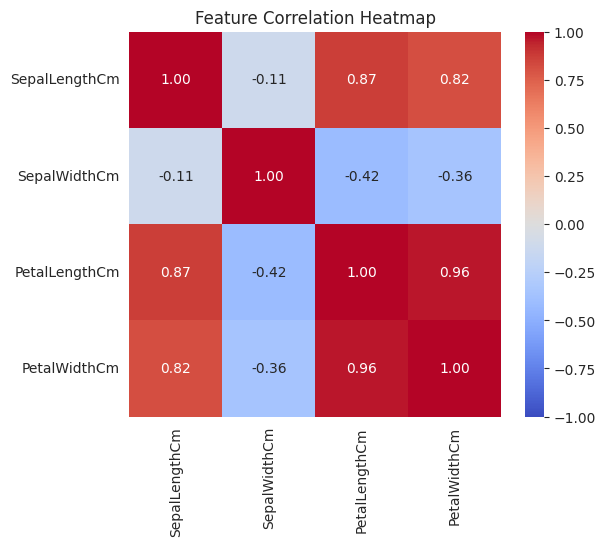

In [12]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_clean[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap")
plt.show()

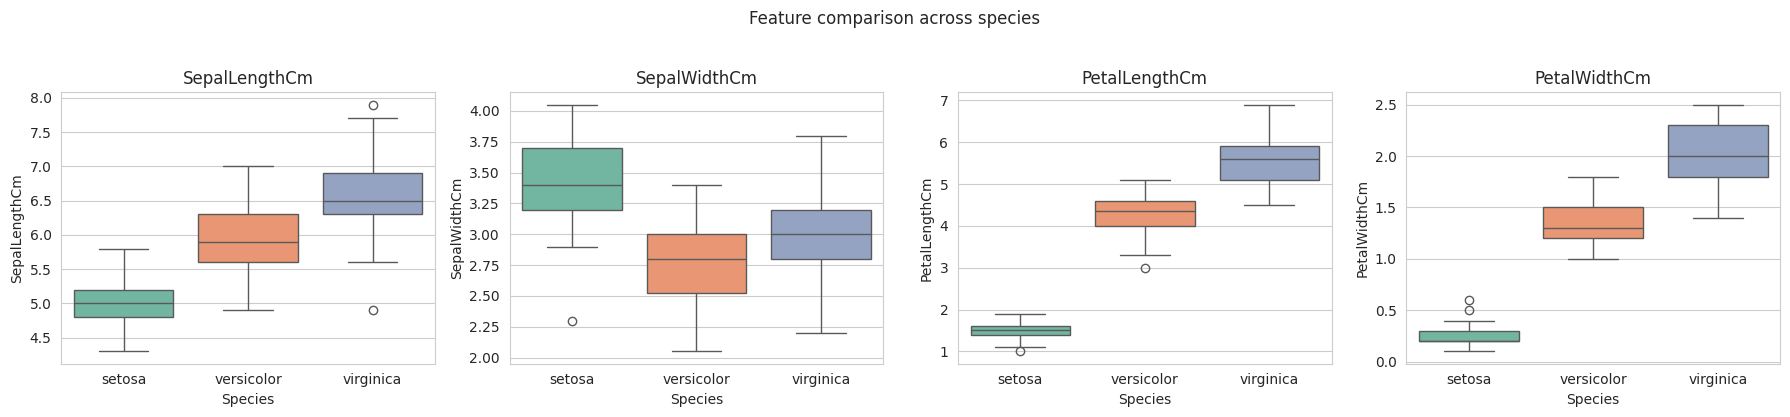

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df_clean, x="Species", y=col, ax=ax, palette="Set2")
    ax.set_title(col)
plt.suptitle("Feature comparison across species", y=1.03)
plt.tight_layout()
plt.show()

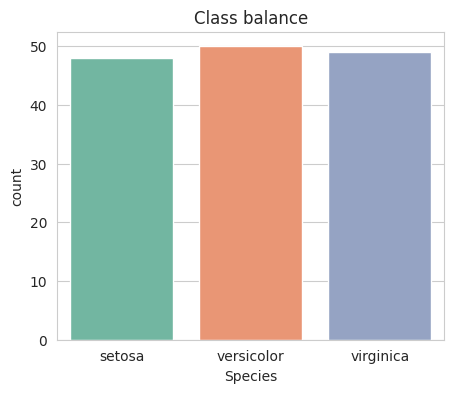

In [14]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df_clean, x="Species", palette="Set2")
plt.title("Class balance")
plt.show()

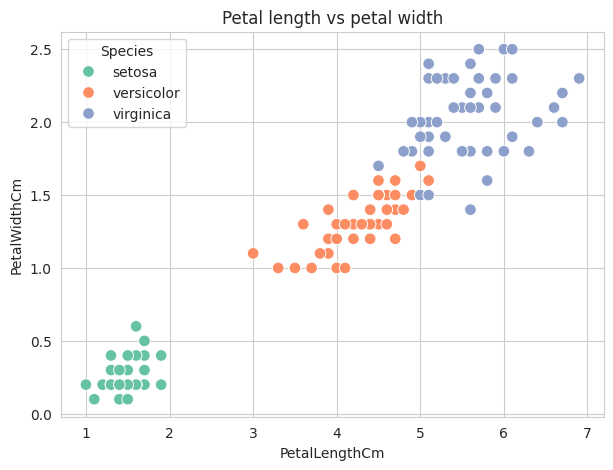

In [15]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="PetalLengthCm", y="PetalWidthCm", hue="Species", s=70, palette="Set2")
plt.title("Petal length vs petal width")
plt.show()

In [16]:
df_clean.groupby("Species")[features].agg(["mean", "std"]).round(2)

SepalLengthCm       SepalWidthCm       PetalLengthCm        \
                    mean   std         mean   std          mean   std   
Species                                                                 
setosa              5.01  0.36         3.42  0.36          1.46  0.18   
versicolor          5.94  0.52         2.77  0.31          4.26  0.47   
virginica           6.60  0.63         2.98  0.32          5.56  0.55   

           PetalWidthCm        
                   mean   std  
Species                        
setosa             0.25  0.11  
versicolor         1.33  0.20  
virginica          2.03  0.28

In [17]:
df_fe = df_clean.copy()

# 1. Petal area (length x width), a proxy for overall petal size
df_fe["PetalArea"] = df_fe["PetalLengthCm"] * df_fe["PetalWidthCm"]

# 2. Sepal area
df_fe["SepalArea"] = df_fe["SepalLengthCm"] * df_fe["SepalWidthCm"]

# 3. Petal aspect ratio (length / width), captures shape not just size
df_fe["PetalRatio"] = df_fe["PetalLengthCm"] / df_fe["PetalWidthCm"].replace(0, np.nan)

# 4. Sepal aspect ratio
df_fe["SepalRatio"] = df_fe["SepalLengthCm"] / df_fe["SepalWidthCm"]

# 5. Petal to sepal area ratio, how big the petal is relative to the flower
df_fe["PetalToSepalArea"] = df_fe["PetalArea"] / df_fe["SepalArea"]

new_feats = ["PetalArea", "SepalArea", "PetalRatio", "SepalRatio", "PetalToSepalArea"]
df_fe[new_feats + ["Species"]].head()

,PetalArea,SepalArea,PetalRatio,SepalRatio,PetalToSepalArea,Species
0,0.28,17.85,7.0,1.457143,0.015686,setosa
1,0.28,14.70,7.0,1.633333,0.019048,setosa
2,0.26,15.04,6.5,1.468750,0.017287,setosa
3,0.30,14.26,7.5,1.483871,0.021038,setosa
4,0.28,18.00,7.0,1.388889,0.015556,setosa


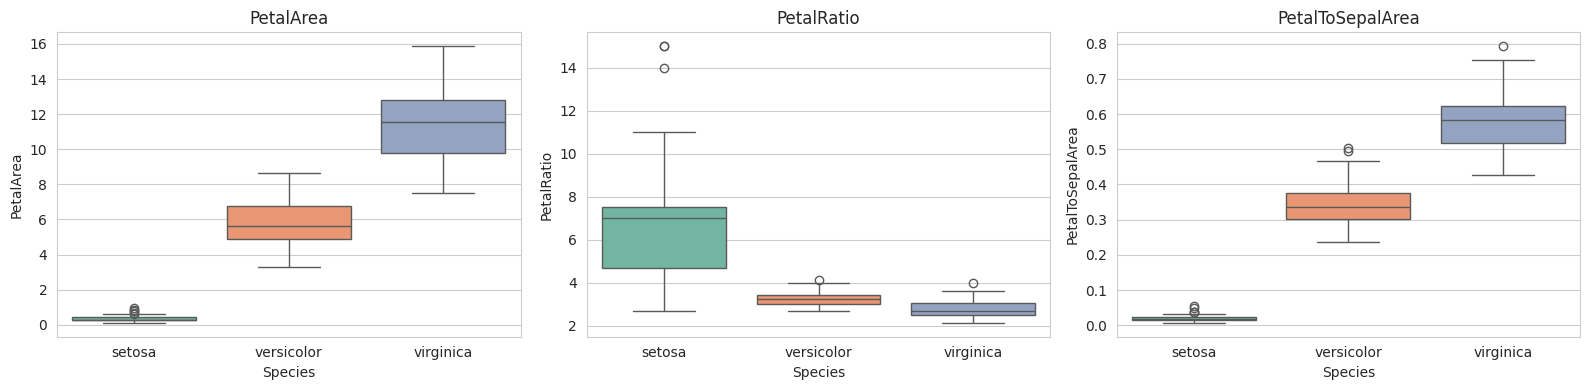

PetalToSepalArea    0.964
PetalWidthCm        0.956
PetalArea           0.949
PetalLengthCm       0.948
SepalLengthCm       0.783
SepalRatio          0.775
PetalRatio          0.682
SepalWidthCm        0.418
SepalArea           0.311
dtype: float64


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["PetalArea", "PetalRatio", "PetalToSepalArea"]):
    sns.boxplot(data=df_fe, x="Species", y=col, ax=ax, palette="Set2")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Correlation of every feature with the species (encoded) as a quick usefulness check
enc = df_fe["Species"].astype("category").cat.codes
print(df_fe[features + new_feats].corrwith(enc).abs().sort_values(ascending=False).round(3))

In [19]:
print("Petal length vs width correlation:", round(df_clean["PetalLengthCm"].corr(df_clean["PetalWidthCm"]), 3))
print("Sepal width vs petal length correlation:", round(df_clean["SepalWidthCm"].corr(df_clean["PetalLengthCm"]), 3))
print("\nSetosa petal length range:", df_clean[df_clean.Species=="setosa"]["PetalLengthCm"].agg(["min","max"]).values)
print("Versicolor petal length range:", df_clean[df_clean.Species=="versicolor"]["PetalLengthCm"].agg(["min","max"]).values)
print("Virginica petal length range:", df_clean[df_clean.Species=="virginica"]["PetalLengthCm"].agg(["min","max"]).values)
print("\nMean PetalArea by species:\n", df_fe.groupby("Species")["PetalArea"].mean().round(2))

Petal length vs width correlation: 0.962
Sepal width vs petal length correlation: -0.42

Setosa petal length range: [1.  1.9]
Versicolor petal length range: [3.  5.1]
Virginica petal length range: [4.5 6.9]

Mean PetalArea by species:
 Species
setosa         0.37
versicolor     5.72
virginica     11.33
Name: PetalArea, dtype: float64


## Key Insights

1. **Clean, balanced data.** There are no missing values, the Id column was dropped, a few duplicate rows were removed, and the classes are balanced at roughly 50 each, so accuracy is a fair metric later.
2. **Outliers are real, not errors.** Only a handful of points fall outside the IQR fences, mostly in sepal width. With 150 rows I capped them instead of deleting them.
3. **Petal features are the strongest signal.** Petal length and petal width are almost perfectly correlated (about 0.96), and both separate species far better than sepal measurements.
4. **Setosa is easy, the other two overlap.** Setosa has clearly smaller petals with no overlap, while versicolor and virginica overlap on sepal size and only partly on petals.
5. **Engineered features add separation.** PetalArea and PetalToSepalArea stretch the gap between species, and are strongly tied to the species label, so they are good candidates for a future model. They are also redundant with the raw petal columns, so watch multicollinearity in linear models.